# Northern Beaches Water Quality — Exceedance Prediction
ENGG2112 · AI for Good

**Goal:** predict whether the next Beachwatch sample at a site will exceed the enterococci guideline (poor = 1, safe = 0).

**Pipeline:** config → load/clean → label → EDA checks → BOM merge → features → chronological split → models (LR / RF / XGBoost) → evaluation

## 0. Imports
If XGBoost isn't installed, run `pip install xgboost` in a terminal first.

In [1]:
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

## 1. Config
Change things here, not further down.
- `SITES`: `'all'` uses every site, or give a list of exact names from the `Swim site` column.
- `FOCUS_SITE`: the site we care most about. Section 11 checks whether training on all sites helps it.
- `THRESHOLD`: poor = enterococci **≥** 41 CFU/100 mL. ⚠️ Check the comparator (≥ vs >) against the NHMRC/Beachwatch source and cite it.
- `RAIN_FILES`: SILO rainfall files (`Name (lat, lon).xlsx`). Each swim site gets the rain from its nearest file.
- `SPLIT_DATE`: everything before → train, on/after → test (chronological).

In [2]:
DATA_PATH = 'Water quality-Data.csv'
RAIN_FILES = sorted(glob.glob('* (*, *).xlsx'))   # 13 SILO files, 2000-01-01 → 2026-10-07

SITES = 'all'           # or e.g. ['Narrabeen Lagoon (Birdwood Park)', 'Bilarong Reserve']
FOCUS_SITE = 'Narrabeen Lagoon (Birdwood Park)'
THRESHOLD = 41
SPLIT_DATE = '2021-01-01'
RANDOM_STATE = 42

## 2. Load & clean

In [3]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the BOM char on the first header
df = df.rename(columns={
    'Swim site': 'site',
    'Enterococci (cfu/100mL)': 'entero',
    'Water temperature (°C)': 'water_temp',
})
df['date'] = pd.to_datetime(df['Date'], dayfirst=True)

print('All sites:', df['site'].nunique())
if SITES != 'all':
    df = df[df['site'].isin(SITES)]
df = df.copy()
print('Rows for selected sites:', len(df))

All sites: 42
Rows for selected sites: 55507


In [4]:
# Missing values before dropping
print(df[['entero', 'water_temp']].isna().sum())

# Water temp has entry errors (e.g. 245, 1616 °C) -> treat implausible values as missing
df.loc[~df['water_temp'].between(5, 35), 'water_temp'] = np.nan

df = df.dropna(subset=['entero'])
df = df.sort_values(['site', 'date']).reset_index(drop=True)
df[['site', 'date', 'entero', 'water_temp']].head()

entero          135
water_temp    23886
dtype: int64


,site,date,entero,water_temp
0,Avalon Beach,2000-01-04,0.0,NaN
1,Avalon Beach,2000-01-11,6.0,NaN
2,Avalon Beach,2000-01-16,12.0,NaN
3,Avalon Beach,2000-01-22,90.0,NaN
4,Avalon Beach,2000-01-28,6.0,NaN


## 3. Target label + class balance

In [5]:
df['poor'] = (df['entero'] >= THRESHOLD).astype(int)

print(df.groupby('site')['poor'].agg(['count', 'mean']).rename(columns={'mean': 'exceed_rate'})
      .sort_values('exceed_rate', ascending=False))

                                  count  exceed_rate
site                                                
Bilarong Reserve                    722     0.324100
Narrabeen Lagoon (Birdwood Park)   1230     0.286992
Davidson Reserve                   1224     0.246732
Sangrado Baths                      593     0.241147
Bayview Baths                      1213     0.228359
Salt Pan Cove Baths                 594     0.178451
Gurney Crescent Baths              1225     0.164898
Queenscliff Beach                  1576     0.145939
Winji Jimmi Bay                     594     0.136364
Shelly Beach (Manly)               1576     0.131345
Clontarf Pool                      1226     0.122349
South Steyne Beach                 1571     0.117123
Little Manly Cove                  1225     0.115918
Manly Cove                         1225     0.107755
Paradise Beach Baths               1215     0.104527
Forty Baskets Pool                 1224     0.099673
Clareville Beach                   1215     0.

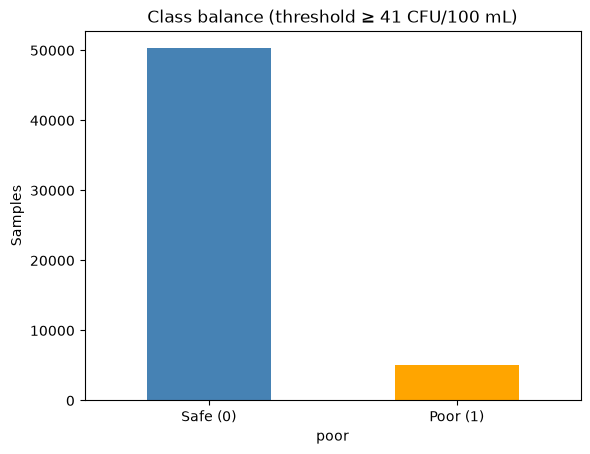

In [6]:
df['poor'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Safe (0)', 'Poor (1)'], rotation=0)
plt.ylabel('Samples')
plt.title(f'Class balance (threshold ≥ {THRESHOLD} CFU/100 mL)')
plt.show()

## 4. EDA sanity checks
Sampling interval (should be ~6 days) and exceedance over time (watch for drift between train and test years).

In [7]:
gaps = df.groupby('site')['date'].diff().dt.days
print(gaps.describe())

count    55330.000000
mean         6.877300
std          4.632439
min          0.000000
25%          6.000000
50%          6.000000
75%          7.000000
max        124.000000
Name: date, dtype: float64


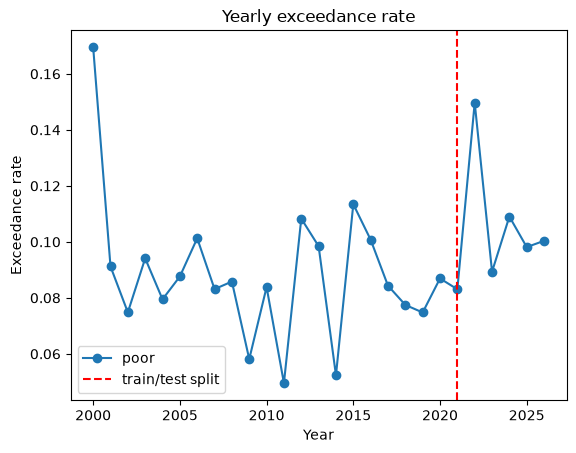

In [8]:
yearly = df.groupby(df['date'].dt.year)['poor'].mean()
yearly.plot(marker='o')
plt.axvline(pd.Timestamp(SPLIT_DATE).year, color='red', ls='--', label='train/test split')
plt.ylabel('Exceedance rate'); plt.xlabel('Year'); plt.legend()
plt.title('Yearly exceedance rate')
plt.show()

## 5. Rainfall merge (SILO)
Daily rainfall from **SILO** (built from BOM observations, gap-free). 13 files:
- **11 grid points** ("Data Drill"): interpolated estimates on a 0.05° grid. The town name is just a label.
- **2 real stations** ("Patched Point"): Mona Vale Golf Club (66141) and Palm Beach Sunrise Rd (66128), gaps filled by SILO. Their true coordinates are read from inside the file (the file names are rounded).

Each swim site is matched to its **nearest** rain point (several sites can share one).

Notes:
- ⚠️ Cite SILO as the data source (CC BY 4.0 licence requires it).
- ⚠️ To verify: SILO daily rain for date D should be the 24h to **9am on D** (BOM convention). Confirm in SILO's documentation and cite it.

In [10]:
def load_silo(path):
    """Read one SILO xlsx -> (lat, lon, daily rainfall Series indexed by date)."""
    raw = pd.read_excel(path, header=None)

    # Coordinates are in the notes block, e.g. 'Lat, Long: -33.80 151.25' or 'Lat: -33.6795 Long: 151.3076'
    notes = ' '.join(str(v) for v in raw[0].head(40))
    lat, lon = map(float, re.search(r'Lat(?:, Long)?:\s*(-?\d+\.\d+)\s*(?:Long:)?\s*(-?\d+\.\d+)', notes).groups())

    # Table starts at the 'Date' header row, then a units row, then data
    h = raw.index[raw[0].astype(str).str.strip() == 'Date'][0]
    d = raw.iloc[h + 2:].copy()
    d.columns = raw.iloc[h].astype(str).str.strip()
    d = d[pd.to_numeric(d['Date'], errors='coerce').notna()]
    d['date'] = pd.to_datetime(d['Date'].astype(int).astype(str), format='%Y%m%d')
    return lat, lon, d.set_index('date')['Rain'].astype(float)

points = {}
for f in RAIN_FILES:
    lat, lon, rain = load_silo(f)
    points[f.split(' (')[0]] = {'lat': lat, 'lon': lon, 'rain': rain}
print(len(points), 'rain points loaded')

13 rain points loaded


In [11]:
# Match each swim site to its nearest rain point (straight-line km, fine at this scale)
def nearest_point(lat, lon):
    dist = {name: 111.2 * np.hypot(p['lat'] - lat, (p['lon'] - lon) * np.cos(np.radians(lat)))
            for name, p in points.items()}
    best = min(dist, key=dist.get)
    return best, dist[best]

site_xy = df.groupby('site')[['Latitude', 'Longitude']].first()
site_map = pd.DataFrame(
    [(site, *nearest_point(r['Latitude'], r['Longitude'])) for site, r in site_xy.iterrows()],
    columns=['site', 'rain_point', 'dist_km']).set_index('site')
site_map.sort_values('rain_point').round(1)

,rain_point,dist_km
site,,
Fairlight Beach,Balgowlah,2.3
Sangrado Baths,Balgowlah,1.1
Forty Baskets Pool,Balgowlah,1.9
Gurney Crescent Baths,Balgowlah,1.5
Clontarf Pool,Balgowlah,0.7
Davidson Reserve,Belrose,2.0
North Curl Curl Beach,Dee Why,2.0
Dee Why Beach,Dee Why,0.4
Collaroy Beach,Dee Why,2.0


In [13]:
# Cumulative rainfall windows per rain point (sum of daily totals ending on the sample date)
RAIN_COLS = ['rain_24h', 'rain_48h', 'rain_72h', 'rain_7d']

frames = []
for name, p in points.items():
    r = p['rain'].asfreq('D')   # one row per day so rolling windows are in days
    frames.append(pd.DataFrame({'rain_point': name, 'rain_24h': r,
                                'rain_48h': r.rolling(2).sum(),
                                'rain_72h': r.rolling(3).sum(),
                                'rain_7d': r.rolling(7).sum()}))
rain_feats = pd.concat(frames).rename_axis('date').reset_index()

df = df.drop(columns=RAIN_COLS + ['rain_point'], errors='ignore')   # safe to re-run this cell
df['rain_point'] = df['site'].map(site_map['rain_point'])
df = df.merge(rain_feats, on=['rain_point', 'date'], how='left')
print(df[RAIN_COLS].isna().sum())   # only the first few days of 2000 (not enough history for the window)

rain_24h     0
rain_48h     0
rain_72h     8
rain_7d     39
dtype: int64


In [14]:
# Sanity check: exceedance rate by 72h rainfall band
bands = pd.cut(df['rain_72h'], [-0.1, 0, 5, 20, 50, np.inf],
               labels=['0', '0-5', '5-20', '20-50', '50+'])
print(df.groupby(bands, observed=True)['poor'].agg(['count', 'mean']).rename(columns={'mean': 'exceed_rate'}))

          count  exceed_rate
rain_72h                    
0         15527     0.029690
0-5       20259     0.046202
5-20      11667     0.116654
20-50      5313     0.226802
50+        2598     0.438029


## 6. Feature engineering
Features are the inputs the model sees for each sample. Only use info that's known **before** the sample is taken (no leakage).
- **Sample history:** previous result at the same site, days since it, previous water temp (water temp is measured *at* sampling, so same-day temp isn't allowed).
- **Season:** month as sin/cos so Dec and Jan count as close.
- **Rainfall:** from Section 5, using each site's nearest rain point.
- **Site:** lets one model tell lagoons from open beaches (next cell).

In [15]:
g = df.groupby('site')

df['prev_entero_log'] = np.log1p(g['entero'].shift(1))
df['prev_poor'] = g['poor'].shift(1)
df['days_since_prev'] = g['date'].diff().dt.days
df['prev_water_temp'] = g['water_temp'].shift(1)
df['month_sin'] = np.sin(2 * np.pi * df['date'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['date'].dt.month / 12)

In [16]:
# Site features
# site_rate = each site's exceedance rate in the TRAINING years only (using test years would leak the answers)
is_train = df['date'] < SPLIT_DATE
train_rates = df[is_train].groupby('site')['poor'].mean()
df['site_rate'] = df['site'].map(train_rates).fillna(df.loc[is_train, 'poor'].mean())   # fallback for sites with no training data

print(train_rates.sort_values(ascending=False).round(3).head(10))

site
Narrabeen Lagoon (Birdwood Park)    0.277
Bilarong Reserve                    0.258
Davidson Reserve                    0.247
Sangrado Baths                      0.241
Bayview Baths                       0.206
Salt Pan Cove Baths                 0.178
Gurney Crescent Baths               0.156
Queenscliff Beach                   0.138
Winji Jimmi Bay                     0.136
Clontarf Pool                       0.117
Name: poor, dtype: float64


In [17]:
FEATURES = [
    'prev_entero_log', 'prev_poor', 'days_since_prev', 'prev_water_temp',   # sample history
    'month_sin', 'month_cos',                                              # season
    'rain_24h', 'rain_48h', 'rain_72h', 'rain_7d',                         # rainfall
    'site_rate', 'Latitude', 'Longitude',                                  # site
]

df = df.dropna(subset=['prev_poor'])   # first sample per site has no history
df[FEATURES].describe().round(2)

,prev_entero_log,prev_poor,days_since_prev,prev_water_temp,month_sin,month_cos,rain_24h,rain_48h,rain_72h,rain_7d,site_rate,Latitude,Longitude
count,55330.00,55330.00,55330.00,31433.00,55330.00,55330.00,55330.00,55330.00,55330.00,55330.00,55330.00,55330.00,55330.00
mean,1.42,0.09,6.88,19.80,0.03,0.05,3.08,6.66,9.84,22.87,0.09,-33.71,151.30
std,1.59,0.29,4.63,2.85,0.71,0.70,9.17,16.33,21.09,34.88,0.06,0.07,0.03
min,0.00,0.00,0.00,9.00,-1.00,-1.00,0.00,0.00,0.00,0.00,0.02,-33.81,151.20
25%,0.00,0.00,6.00,18.00,-0.50,-0.50,0.00,0.00,0.00,2.00,0.05,-33.79,151.29
50%,1.10,0.00,6.00,20.00,0.00,0.00,0.00,0.40,1.50,10.15,0.07,-33.70,151.30
75%,2.30,0.00,7.00,22.00,0.87,0.87,1.50,5.50,10.10,28.40,0.11,-33.64,151.31
max,11.49,1.00,124.00,29.00,1.00,1.00,171.20,199.40,299.30,417.50,0.28,-33.59,151.33


## 7. Chronological train/test split
Rows are sorted by date (not by site) so the cross-validation in Section 9 always trains on the past and validates on the future.

In [18]:
train = df[df['date'] < SPLIT_DATE].sort_values('date')
test = df[df['date'] >= SPLIT_DATE].sort_values('date')

X_train, y_train = train[FEATURES], train['poor']
X_test, y_test = test[FEATURES], test['poor']

print(f'Train: {len(train)} rows, {train.site.nunique()} sites, {train.date.min().date()} → {train.date.max().date()}, poor rate {y_train.mean():.3f}')
print(f'Test:  {len(test)} rows, {test.site.nunique()} sites, {test.date.min().date()} → {test.date.max().date()}, poor rate {y_test.mean():.3f}')

Train: 44327 rows, 42 sites, 2000-01-07 → 2020-12-17, poor rate 0.089
Test:  11003 rows, 39 sites, 2021-01-04 → 2026-09-21, poor rate 0.105


## 8. Define the models
These are untrained "recipes" so far. All three handle class imbalance by giving poor days more weight. The imputer fills missing `prev_water_temp` and rainfall gaps (median, learned from training data only, inside the pipeline).

In [19]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000)),
    ]),
    'Random Forest': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                       min_samples_leaf=5, random_state=RANDOM_STATE)),
    ]),
    'XGBoost': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('clf', XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                              scale_pos_weight=pos_weight, eval_metric='logloss',
                              random_state=RANDOM_STATE)),
    ]),
}

## 9. Train the models
Training = the model looks at the training rows (features + the real answer) and adjusts itself to map one to the other. The test set is **not touched** here.

**Step 1: cross-validation (training years only).** `TimeSeriesSplit` cuts the training years into 5 chunks in date order. Each round trains on the earlier chunks and validates on the next one, like forecasting. The average score is our honest estimate before looking at the test set, and it's what we'll use later to tune settings and pick a model.

**Step 2: final fit.** Retrain each model on *all* training years. Training-set scores are shown for comparison: if they're much higher than the CV scores, the model is memorising (overfitting).

In [20]:
# Step 1: time-series cross-validation on the training years
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=tscv, scoring=['recall', 'f1'])
    cv_rows.append({
        'model': name,
        'CV recall (poor)': scores['test_recall'].mean(),
        'CV F1 (poor)': scores['test_f1'].mean(),
        'F1 spread across folds (std)': scores['test_f1'].std(),
    })
cv_results = pd.DataFrame(cv_rows).set_index('model').round(3)
cv_results

,CV recall (poor),CV F1 (poor),F1 spread across folds (std)
model,,,
Logistic Regression,0.740,0.370,0.026
Random Forest,0.599,0.457,0.037
XGBoost,0.701,0.394,0.037


In [21]:
# Step 2: final fit on all training years
train_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_train)
    train_rows.append({'model': name,
                       'train recall (poor)': recall_score(y_train, pred),
                       'train F1 (poor)': f1_score(y_train, pred)})

# Big gap between train F1 and CV F1 = overfitting
pd.DataFrame(train_rows).set_index('model').join(cv_results[['CV F1 (poor)']]).round(3)

,train recall (poor),train F1 (poor),CV F1 (poor)
model,,,
Logistic Regression,0.693,0.397,0.370
Random Forest,0.989,0.740,0.457
XGBoost,0.729,0.443,0.394


## 10. Evaluation on the test set (2021+)
Primary: **recall** and **F1** on the poor class. Accuracy shown for context only (it's inflated by the many safe ocean-beach days).

In [22]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        'model': name,
        'recall (poor)': recall_score(y_test, pred),
        'precision (poor)': precision_score(y_test, pred, zero_division=0),
        'F1 (poor)': f1_score(y_test, pred),
        'accuracy': accuracy_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index('model').round(3)
results

,recall (poor),precision (poor),F1 (poor),accuracy
model,,,,
Logistic Regression,0.768,0.310,0.442,0.795
Random Forest,0.624,0.439,0.515,0.876
XGBoost,0.748,0.337,0.465,0.819


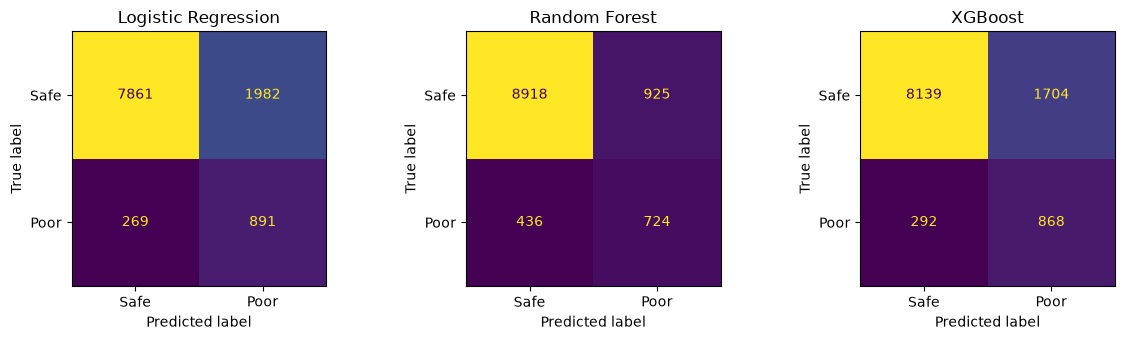

In [23]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=['Safe', 'Poor']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [24]:
# Per-site results for the model with the best CV F1 (chosen without peeking at the test set)
best = cv_results['CV F1 (poor)'].idxmax()
test_pred = test.assign(pred=models[best].predict(X_test))

site_rows = []
for site, s in test_pred.groupby('site'):
    site_rows.append({'site': site, 'samples': len(s), 'poor days': s['poor'].sum(),
                      'recall (poor)': recall_score(s['poor'], s['pred'], zero_division=0),
                      'F1 (poor)': f1_score(s['poor'], s['pred'], zero_division=0)})
print('Model:', best)
pd.DataFrame(site_rows).set_index('site').sort_values('poor days', ascending=False).round(3)

Model: Random Forest


,samples,poor days,recall (poor),F1 (poor)
site,,,,
Bilarong Reserve,330,133,0.767,0.624
Narrabeen Lagoon (Birdwood Park),329,103,0.845,0.584
Bayview Baths,212,71,0.521,0.487
Shelly Beach (Manly),334,70,0.429,0.462
Queenscliff Beach,334,59,0.780,0.672
Davidson Reserve,218,54,0.944,0.675
South Steyne Beach,328,47,0.468,0.411
Gurney Crescent Baths,218,45,0.800,0.626
Freshwater Beach,335,36,0.417,0.349


## 11. Did expanding to all sites help the focus site?
Same models, trained on the focus site only, compared with the all-sites models, both scored on the focus site's test rows. If "all sites" wins, the extra data is helping.

In [25]:
focus_train = train[train['site'] == FOCUS_SITE]
focus_test = test[test['site'] == FOCUS_SITE]

rows = []
for name, model in models.items():
    solo = clone(model)
    if name == 'XGBoost':   # re-balance for the focus site's own class ratio
        solo.set_params(clf__scale_pos_weight=(focus_train['poor'] == 0).sum() / focus_train['poor'].sum())
    solo.fit(focus_train[FEATURES], focus_train['poor'])

    for trained_on, m in [('all sites', model), ('focus site only', solo)]:
        pred = m.predict(focus_test[FEATURES])
        rows.append({'model': name, 'trained on': trained_on,
                     'recall (poor)': recall_score(focus_test['poor'], pred),
                     'F1 (poor)': f1_score(focus_test['poor'], pred)})

print('Focus site:', FOCUS_SITE, '| test rows:', len(focus_test))
pd.DataFrame(rows).set_index(['model', 'trained on']).round(3)

Focus site: Narrabeen Lagoon (Birdwood Park) | test rows: 329


recall (poor)  F1 (poor)
model               trained on                               
Logistic Regression all sites                1.000      0.477
                    focus site only          0.660      0.642
Random Forest       all sites                0.845      0.584
                    focus site only          0.631      0.637
XGBoost             all sites                0.942      0.501
                    focus site only          0.583      0.594

## 12. Next steps — TODO
- [x] SILO rainfall merged per site, nearest of 13 points (Section 5)
- [x] Expanded to all sites with site features (Section 6)
- [ ] Decision-threshold tuning using CV on the training years (never on test)
- [ ] Hyperparameter tuning with `TimeSeriesSplit`
- [ ] Feature importance / LR coefficients for interpretability
- [ ] Site-type feature (lagoon / harbour / ocean beach) or catchment data — stretch goal
- [ ] Upstream catchment rain (e.g. Ingleside / Terrey Hills points feed Narrabeen Lagoon) as an extra feature
- [ ] SILO also has max/min temp, evaporation, radiation, humidity: candidate features